### Cell 1: imports

In [17]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker

### PDE, grid and reference solution
Kuramoto–Sivashinsky $u_t + u\,u_x + u_{xx} + u_{xxxx} = 0$ on $[0, L]$, $L = 22$ (chaotic regime), rescaled to $x\in[0,1]$:
$u_t + \tfrac1L u\,u_x + \tfrac1{L^2}u_{xx} + \tfrac1{L^4}u_{xxxx} = 0$. IC $u_0 = \cos(2\pi x)\,(1 + \sin(2\pi x))$, horizon $T = 10$ (under half a Lyapunov time).
**Reference** ("exact"): Fourier pseudo-spectral + ETDRK4 (Kassam & Trefethen 2005), $N = 256$ modes, $\Delta t = 0.005$, far finer than any method in the comparison; checked against the same run at half the step.
The solution is periodic, but the method keeps its walls: the outer **2 columns** on each side are known data from the reference (a 4th-order PDE needs 2 conditions per side), like the IC. The reference is only used for this data, checks and reports, never by the agent.

KS: L = 22.0, T = 10.0 | nx = 50, dx = 0.449 (physical), nt = 201, dt = 0.050 | explicit FD-RK4 limit ~ 0.0068 -> our dt is 7x it
check: reference, dt vs dt/2 at t =  2.50: max difference 4.3e-10  (max |u| = 2.21)
check: reference, dt vs dt/2 at t =  5.00: max difference 1.7e-10  (max |u| = 2.17)
check: reference, dt vs dt/2 at t = 10.00: max difference 6.3e-11  (max |u| = 1.90)


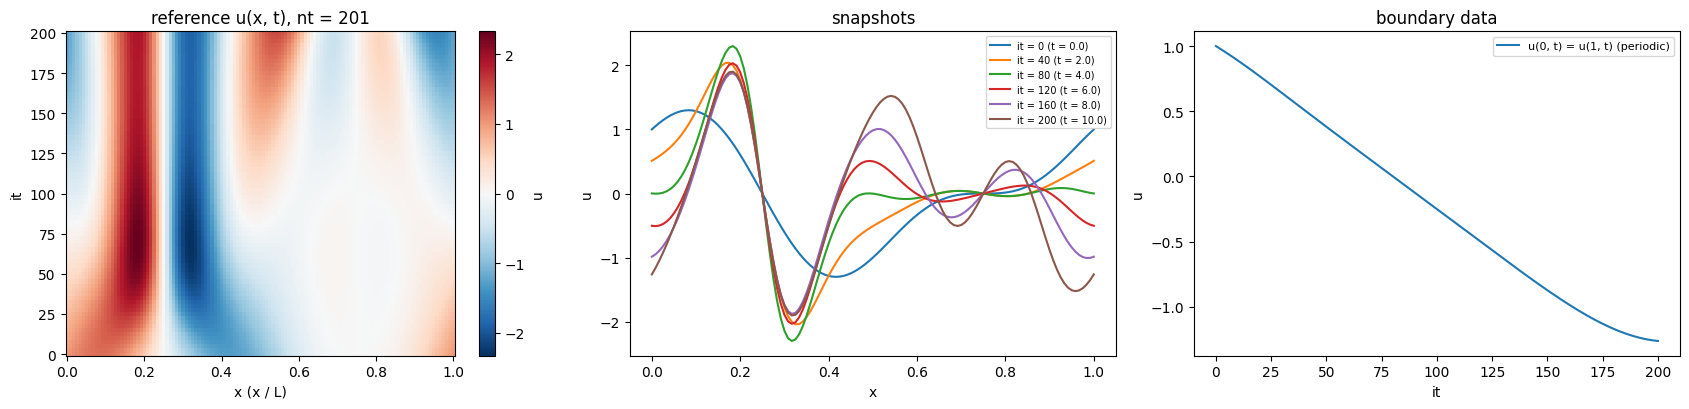

In [18]:
# ── PDE: Kuramoto-Sivashinsky  u_t + u u_x + u_xx + u_xxxx = 0  on [0, L], periodic; rescaled to x in [0, 1] ──
#   in x in [0, 1]:  u_t + C1 u u_x + C2 u_xx + C4 u_xxxx = 0,  C1 = 1/L, C2 = 1/L^2, C4 = 1/L^4
L_KS, T = 22.0, 10.0
C1, C2, C4 = 1 / L_KS, 1 / L_KS**2, 1 / L_KS**4
u0 = lambda x: np.cos(2 * np.pi * np.asarray(x, dtype=float)) * (1 + np.sin(2 * np.pi * np.asarray(x, dtype=float)))
N_WALL = 2                                                   # known columns on each side (data from the reference)

# ── Reference: Fourier pseudo-spectral + ETDRK4 (Kassam & Trefethen 2005), stored at every step ──
N_REF, DT_REF = 256, 0.005
def ks_etdrk4(N, h, T_end):
    """Fourier coefficients v[s] of u at t = s h, s = 0..T_end/h (physical x in [0, L))."""
    xp = L_KS * np.arange(N) / N
    v  = np.fft.fft(u0(xp / L_KS))
    k  = 2 * np.pi / L_KS * np.fft.fftfreq(N, 1.0 / N)
    Lk = k**2 - k**4                                         # linear operator: - u_xx - u_xxxx
    E, E2 = np.exp(h * Lk), np.exp(h * Lk / 2)
    r  = np.exp(1j * np.pi * (np.arange(1, 17) - 0.5) / 16)  # contour points for the phi functions
    LR = h * Lk[:, None] + r[None, :]
    Q  = h * np.real(np.mean((np.exp(LR / 2) - 1) / LR, axis=1))
    f1 = h * np.real(np.mean((-4 - LR + np.exp(LR) * (4 - 3 * LR + LR**2)) / LR**3, axis=1))
    f2 = h * np.real(np.mean((2 + LR + np.exp(LR) * (-2 + LR)) / LR**3, axis=1))
    f3 = h * np.real(np.mean((-4 - 3 * LR - LR**2 + np.exp(LR) * (4 - LR)) / LR**3, axis=1))
    g  = -0.5j * k                                           # nonlinear term: -(u^2 / 2)_x
    Nl = lambda v: g * np.fft.fft(np.real(np.fft.ifft(v))**2)
    steps = int(round(T_end / h))
    V = np.empty((steps + 1, N), dtype=complex); V[0] = v
    for s in range(steps):
        Nv = Nl(v); a_ = E2 * v + Q * Nv
        Na = Nl(a_); b_ = E2 * v + Q * Na
        Nb = Nl(b_); c_ = E2 * a_ + Q * (2 * Nb - Nv)
        Nc = Nl(c_)
        v = E * v + Nv * f1 + 2 * (Na + Nb) * f2 + Nc * f3
        V[s + 1] = v
    return V

V_REF = ks_etdrk4(N_REF, DT_REF, T)
_kp = 2 * np.pi * np.fft.fftfreq(N_REF, 1.0 / N_REF)        # wavenumbers in x in [0, 1]
_kp[N_REF // 2] = 0.0                                        # Nyquist mode: drop (real evaluation off the grid)

def u_true(x, t):
    """Reference u at any x in [0, 1] (exact Fourier evaluation) and t on the reference time grid."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    s = int(round(t / DT_REF))
    assert abs(s * DT_REF - t) < 1e-9 and 0 <= s < len(V_REF), f"t = {t} is not on the reference time grid"
    v = V_REF[s].copy(); v[N_REF // 2] = 0.0
    return np.real(np.exp(1j * np.outer(x, _kp)) @ v) / N_REF

# ── Grid: nx points in x; time step DT (a multiple of DT_REF), to be set from the admissible stencils ──
nx = 50
dx = 1.0 / (nx - 1)
DT = 0.05
dt = DT_REF * int(round(DT / DT_REF))
nt = int(round(T / dt)) + 1
x_grid = np.arange(nx) * dx

_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data (the outer columns): a cubic spline in t through the reference (for refined classical schemes) ──
from scipy.interpolate import CubicSpline
_tb = np.arange(0.0, T + DT_REF / 2, 10 * DT_REF)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])
_gs = CubicSpline(_tb, _gb)
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

dxp = L_KS * dx                                              # physical grid spacing
dt_rk4 = 2.8 / (16 / dxp**4 + 4 / dxp**2)                    # explicit FD (2nd order) + RK4 stability limit, roughly
print(f"KS: L = {L_KS}, T = {T} | nx = {nx}, dx = {dxp:.3f} (physical), nt = {nt}, dt = {dt:.3f} | "
      f"explicit FD-RK4 limit ~ {dt_rk4:.4f} -> our dt is {dt / dt_rk4:.0f}x it")

# ── Check: the reference against the same run at half the step (should be ~ round-off) ──
V_half = ks_etdrk4(N_REF, DT_REF / 2, T)
for t in (T / 4, T / 2, T):
    s = int(round(t / DT_REF))
    d = np.abs(np.real(np.fft.ifft(V_REF[s])) - np.real(np.fft.ifft(V_half[2 * s]))).max()
    print(f"check: reference, dt vs dt/2 at t = {t:5.2f}: max difference {d:.1e}  (max |u| = {np.abs(np.fft.ifft(V_REF[s])).max():.2f})")
del V_half

# ── Pictures: u(x, t), snapshots, boundary data ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="RdBu_r")
fig.colorbar(im, ax=axes[0], label="u")
axes[0].set_xlabel("x (x / L)"); axes[0].set_ylabel("it"); axes[0].set_title(f"reference u(x, t), nt = {nt}")
for it in np.linspace(0, nt - 1, 6).round().astype(int):
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it} (t = {it * dt:.1f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="u(0, t) = u(1, t) (periodic)")
axes[2].set_xlabel("it"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
plt.tight_layout(); plt.show()

### Taylor weights, any order
At $p$ the PDE is frozen: $u_t=-a\,u_x+\sum_m\ell_m\partial_x^m u$, with $a$ the speed at $p$ (KS: $a=C_1u_p$ from the guess, $\ell_2=-C_2$, $\ell_4=-C_4$). For a frozen operator a neighbour's value is exactly
$$u(x+\Delta x,t+\Delta t)=e^{\Delta x\,\partial+\Delta t(-a\partial+\sum_m\ell_m\partial^m)}u=\sum_{n\ge0}c_n(\Delta x,\Delta t)\,\partial_x^nu ,$$
so the weights satisfy $\sum_q w_q c_n(q)=\delta_{n0}$ for $n<N_{\rm rows}$. $N_{\rm rows}=3$ gives back the old rows $(1,\ \xi,\ \tfrac12\xi^2+\alpha\Delta t)$; $N_{\rm rows}=5$ cancels the terms up to $\partial_x^4u$ (higher order).
Rows scaled by $h^{-n}$, $h=\max\big(|\Delta x|,\max_m(|\ell_m\Delta t|)^{1/m}\big)$. Min-norm solution; admissible if rank $N_{\rm rows}$, $\mathrm{cond}\le10^4$ and $\|w\|_1\le2$.
Checks: the old rows are recovered; on a Fourier mode of the frozen operator the local error falls like $k^{N_{\rm rows}}$; the share of admissible 6-point stencils for several time steps.

In [19]:
# ── Taylor predictor, any order: N_ROWS rows of the FROZEN operator  u_t = -a u_x + sum_m LIN[m] d^m u ──
#   u(x + DX, t + DT) = exp(P(d)) u = sum_n c_n(DX, DT) d^n u,   P(z) = (DX - a DT) z + DT sum_m LIN[m] z^m
#   rows: sum_q w_q c_n(q) = [n == 0], n < N_ROWS.  N_ROWS = 3 gives back the old rows (1, xi, xi^2/2 + alpha DT)
LIN = {2: -C2, 4: -C4}                                                # KS: u_t = -C1 u u_x - C2 u_xx - C4 u_xxxx
N_ROWS, N_MAX = 5, 8                                                  # rows in the weights; series kept up to d^N_MAX
COND_MAX, W_MAX = 1e4, 2.0
N_SOLVES = [0]                                                        # weight systems solved so far (cost metric)

def _pmul(A, B, n_max):
    """Product of two polynomials in z (coefficients on the last axis), truncated at degree n_max."""
    out = np.zeros_like(A)
    for i in range(n_max + 1):
        out[..., i:] += A[..., i:i + 1] * B[..., :n_max + 1 - i]
    return out

def series_coeffs(DX, DT, a_loc, lin=None, n_max=N_MAX):
    """c_n(DX, DT), n = 0..n_max (last axis): the coefficients of exp(P(z)). P has no constant term, so n_max terms suffice."""
    lin = LIN if lin is None else lin
    P = np.zeros(np.shape(DX) + (n_max + 1,))
    P[..., 1] = DX - a_loc * DT
    for m, c in lin.items():
        if m <= n_max:
            P[..., m] += c * DT
    out = np.zeros_like(P); out[..., 0] = 1.0
    term = out.copy()
    for k in range(1, n_max + 1):
        term = _pmul(term, P, n_max) / k
        out += term
    return out

def solve_weights_many(DX, DT, a_loc, rows=None, lin=None):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n), a_loc = frozen speed at p.
    Returns W (M, n) and ok (M,): admissible = rank `rows`, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    rows = N_ROWS if rows is None else rows
    lin = LIN if lin is None else lin
    N_SOLVES[0] += DX.shape[0]
    C = series_coeffs(DX, DT, a_loc, lin)[..., :rows]                 # (M, n, rows)
    h = np.abs(DX).max(1)
    for m, c in lin.items():
        h = np.maximum(h, (abs(c) * np.abs(DT).max(1))**(1 / m))
    A = np.swapaxes(C, 1, 2) / h[:, None, None]**np.arange(rows)[None, :, None]   # (M, rows, n), row n scaled by h^-n
    s = np.linalg.svd(A, compute_uv=False)
    ok = (DX.shape[1] >= rows) & (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W = np.linalg.pinv(A) @ np.eye(rows)[0]
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc, rows=None):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc, rows)
    return W[0] if ok[0] else None

# ── Check 1: N_ROWS = 3 with a diffusion term gives back the old rows (1, xi, xi^2/2 + alpha DT) ──
_DX, _DT, _a, _al = np.array([-0.03, 0.0, 0.02]), np.array([-0.01, -0.02, -0.01]), 0.7, 0.1
_c = series_coeffs(_DX, _DT, _a, lin={2: _al})[..., :3]
_xi = _DX - _a * _DT
print("check 1, old rows recovered:", np.allclose(_c, np.stack([np.ones(3), _xi, _xi**2 / 2 + _al * _DT], -1)))

# ── Check 2: order. Local error of one stencil on a Fourier mode of the frozen operator, exp(i k x + lam t),
#    lam = -i a k + sum LIN[m] (i k)^m: the error should fall like k^N_ROWS ──
_a   = C1 * 1.0                                                       # frozen speed for u = 1
_off = np.array([(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1), (0, -2)])          # 6 cells: row below + one 2 levels down
_DX, _DT = _off[:, 0] * dx, _off[:, 1] * dt
ks = 2 * np.pi * np.array([1, 2, 4, 8])
for rows in (3, 5):
    w = solve_weights(_DX, _DT, _a, rows)
    if w is None:
        print(f"check 2, {rows} rows: this stencil is not admissible at dt = {dt}"); continue
    lam = lambda k: -1j * _a * k + sum(c * (1j * k)**m for m, c in LIN.items())
    err = [abs(1 - w @ np.exp(1j * k * _DX + lam(k) * _DT)) for k in ks]
    slope = np.diff(np.log(err)) / np.diff(np.log(ks))
    print(f"check 2, {rows} rows: |w|_1 = {np.abs(w).sum():.2f}, error at k = 2pi*(1,2,4,8): "
          + " ".join(f"{e:.1e}" for e in err) + " | slopes " + " ".join(f"{s_:.1f}" for s_ in slope))

# ── Check 3: share of admissible 6-point stencils in the 21-cell window (|dix| <= 3, 1-3 levels down), several dt ──
_cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]
_sets  = np.array(list(itertools.combinations(range(len(_cells)), 6)))
_offs  = np.array(_cells)[_sets]                                      # (M, 6, 2)
print(f"check 3: {len(_sets)} candidate 6-point stencils, frozen speed {_a:.3f}")
for dt_test in (0.01, 0.02, 0.05, 0.1, 0.2):
    for rows in (3, 5):
        W, ok = solve_weights_many(_offs[..., 0] * dx, _offs[..., 1] * dt_test, _a, rows)
        print(f"   dt = {dt_test:5.2f}, {rows} rows: {ok.mean() * 100:5.1f}% admissible")

check 1, old rows recovered: True
check 2, 3 rows: |w|_1 = 1.60, error at k = 2pi*(1,2,4,8): 4.5e-04 6.5e-03 1.0e-01 4.6e+00 | slopes 3.9 4.0 5.5
check 2, 5 rows: this stencil is not admissible at dt = 0.05
check 3: 54264 candidate 6-point stencils, frozen speed 0.045
   dt =  0.01, 3 rows:  94.3% admissible
   dt =  0.01, 5 rows:  36.3% admissible
   dt =  0.02, 3 rows:  92.7% admissible
   dt =  0.02, 5 rows:  23.5% admissible
   dt =  0.05, 3 rows:  84.5% admissible
   dt =  0.05, 5 rows:  12.2% admissible
   dt =  0.10, 3 rows:  64.6% admissible
   dt =  0.10, 5 rows:   9.2% admissible
   dt =  0.20, 3 rows:  44.1% admissible
   dt =  0.20, 5 rows:   5.6% admissible


In [20]:
# ── Order check on admissible stencils + choice of dt: per dt, the most accurate admissible stencil (on the k = 2 pi mode)
#    for 3 and 5 rows; error at k = 2 pi (1, 2, 4), slopes, and error per unit time (global error ~ local error x steps) ──
lam = lambda k: -1j * _a * k + sum(c * (1j * k)**m for m, c in LIN.items())
ks  = 2 * np.pi * np.array([1, 2, 4])
print(f"{'dt':>5s} {'rows':>4s} {'admissible':>10s} | {'error at k = 2pi, 4pi, 8pi':28s} | {'slopes':10s} | {'error / dt (k = 2pi)':>20s} | |w|_1")
for dt_test in (0.01, 0.02, 0.05, 0.1, 0.2):
    DXs, DTs = _offs[..., 0] * dx, _offs[..., 1] * dt_test
    for rows in (3, 5):
        W, ok = solve_weights_many(DXs, DTs, _a, rows)
        E = np.array([np.abs(1 - (W[ok] * np.exp(1j * k * DXs[ok] + lam(k) * DTs[ok])).sum(1)) for k in ks])   # (3, M_ok)
        i = int(np.argmin(E[0]))
        e = E[:, i]
        sl = np.diff(np.log(e)) / np.diff(np.log(ks))
        print(f"{dt_test:5.2f} {rows:4d} {ok.sum():10d} | " + " ".join(f"{v:8.1e}" for v in e) + "   | "
              + " ".join(f"{v:4.1f}" for v in sl) + f" | {e[0] / dt_test:20.1e} | {np.abs(W[ok][i]).sum():.2f}")

   dt rows admissible | error at k = 2pi, 4pi, 8pi   | slopes     | error / dt (k = 2pi) | |w|_1
 0.01    3      51198 |  4.2e-07  3.0e-04  1.1e-02   |  9.5  5.2 |              4.2e-05 | 1.47
 0.01    5      19721 |  2.6e-08  7.5e-06  1.0e-03   |  8.2  7.1 |              2.6e-06 | 1.52
 0.02    3      50306 |  4.8e-06  4.1e-04  1.9e-02   |  6.4  5.5 |              2.4e-04 | 1.66
 0.02    5      12778 |  3.3e-07  3.2e-05  3.6e-03   |  6.6  6.8 |              1.7e-05 | 1.92
 0.05    3      45879 |  1.6e-05  5.9e-04  4.1e-02   |  5.2  6.1 |              3.2e-04 | 1.59
 0.05    5       6605 |  3.8e-06  2.2e-04  8.6e-03   |  5.8  5.3 |              7.6e-05 | 1.85
 0.10    3      35078 |  2.0e-05  2.2e-03  1.3e-01   |  6.8  5.9 |              2.0e-04 | 1.94
 0.10    5       4966 |  1.5e-05  8.3e-04  2.8e-02   |  5.8  5.0 |              1.5e-04 | 2.00
 0.20    3      23922 |  1.8e-05  2.9e-03  1.5e-01   |  7.3  5.7 |              9.1e-05 | 1.97
 0.20    5       3027 |  5.2e-05  2.8e-03  8.8e-

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q\approx-\sum_q w_q P_p(\Delta x_q,\Delta t_q)$, $\;s_p=\big|\sum_q w_qP_p\big|$, with
$P_p=\sum \frac{1}{i!\,j!}\,\partial_x^i\partial_t^ju\;\Delta x^i\Delta t^j$ over $0<i+4j\le 8$ ($\Delta t$ counts like $\Delta x^4$, since $C_4\Delta t\sim\Delta x^4$).
Time derivatives from the full (nonlinear) KS equation, $u_t=-C_1uu_x-C_2u_{xx}-C_4u_{xxxx}$:
$$\partial_x^n u_t=-C_1\sum_{k=0}^n\tbinom nk u^{(k)}u^{(n-k+1)}-C_2u^{(n+2)}-C_4u^{(n+4)},\qquad u_{tt}=-C_1(u_tu_x+u\,u_{xt})-C_2u_{xxt}-C_4u_{xxxxt}.$$
So the score needs $u,u_x,\dots,\partial_x^8u$ at $p$. The weights cancel the frozen (linear) part up to $\partial_x^4$; the score also sees the nonlinear part they cannot cancel.
Check: random admissible 6-point stencils (5 rows), score with the **exact** derivatives (spectral, from the reference) vs the true local error, for weight $\le 8$ and $\le 6$.

300 admissible 6-point stencils (5 rows), dt = 0.05, |u_x| from 0.00 to 54.10, true local error from 1.1e-05 to 2.4e-01
weight <= 8: corr(log score, log true error) = 1.00, median |score - true| / true = 0.01, within 2x: 99%
weight <= 6: corr(log score, log true error) = 0.98, median |score - true| / true = 0.05, within 2x: 93%


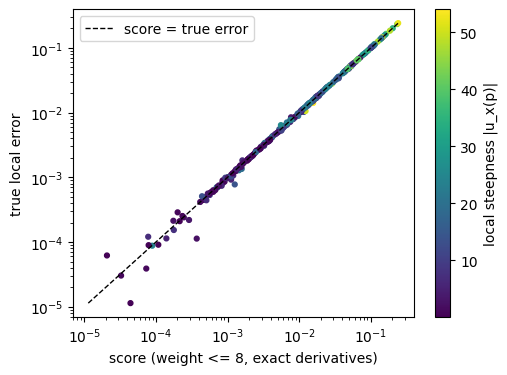

In [21]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
#   terms (i, j) = d_x^i d_t^j u / (i! j!) with 0 < i + 4 j <= W_DEG; time derivatives from the full (nonlinear) KS equation
#   d = (u, u_x, ..., d^8 u) at p
from math import factorial, comb
W_DEG, N_D = 6, 9

def taylor_coeffs(d, w_deg=W_DEG):
    """d = (u, u_x, ..., d^8 u) at p. Returns {(i, j): d_x^i d_t^j u / (i! j!)} for 0 < i + 4 j <= w_deg."""
    d  = np.asarray(d, dtype=float)
    ut = np.array([-C1 * sum(comb(n, k) * d[k] * d[n - k + 1] for k in range(n + 1)) - C2 * d[n + 2] - C4 * d[n + 4]
                   for n in range(5)])                                     # d_x^n u_t, n = 0..4
    utt = -C1 * (ut[0] * d[1] + d[0] * ut[1]) - C2 * ut[2] - C4 * ut[4]
    out = {(i, 0): d[i] / factorial(i) for i in range(1, N_D) if i <= w_deg}
    out.update({(i, 1): ut[i] / factorial(i) for i in range(5) if i + 4 <= w_deg})
    if 8 <= w_deg:
        out[(0, 2)] = utt / 2
    return out

def score(DX, DT, w, d, w_deg=W_DEG):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d, w_deg).items())
    return np.abs((w * P).sum(-1))

def ref_derivs(x, t, n_max=N_D - 1):
    """(u, u_x, ..., d^n_max u) at (x, t), exact: derivatives of the reference's Fourier series (checks only)."""
    v = V_REF[int(round(t / DT_REF))].copy(); v[N_REF // 2] = 0.0
    e = np.exp(1j * _kp * x) * v / N_REF
    return np.array([np.real(((1j * _kp)**n * e).sum()) for n in range(n_max + 1)])

# ── Check: score vs the true local error, random admissible 6-point stencils (5 rows) at random interior points
#    (reference ONLY here); weight <= 8 and weight <= 6 ──
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]
S8, S6, D, G = [], [], [], []
while len(S8) < 300:
    p  = (int(rng.integers(N_WALL + 3, nx - N_WALL - 3)), int(rng.integers(3, nt)))
    nb = [cells[k] for k in rng.choice(len(cells), 6, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = ref_derivs(p[0] * dx, p[1] * dt)
    w = solve_weights(DX, DT, C1 * d[0])                                   # frozen speed from the exact u (check only)
    if w is None:
        continue
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S8.append(score(DX, DT, w, d, 8)); S6.append(score(DX, DT, w, d, 6))
    D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S8, S6, D, G = map(np.array, (S8, S6, D, G))
print(f"300 admissible 6-point stencils (5 rows), dt = {dt}, |u_x| from {G.min():.2f} to {G.max():.2f}, "
      f"true local error from {D.min():.1e} to {D.max():.1e}")
for name, S in [("weight <= 8", S8), ("weight <= 6", S6)]:
    print(f"{name}: corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
          f"median |score - true| / true = {np.median(np.abs(S - D) / D):.2f}, within 2x: {np.mean((S / D > 0.5) & (S / D < 2)) * 100:.0f}%")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S8, D, c=G, s=12, cmap="viridis")
lim = [min(S8.min(), D.min()), max(S8.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (weight <= 8, exact derivatives)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

guess: 24 modes, step 0.10 | cost up to t* = 2.5: 624 points
median error / typical size, d^0 .. d^8 u: 0.000  0.001  0.006  0.020  0.052  0.127  0.206  0.378  0.494


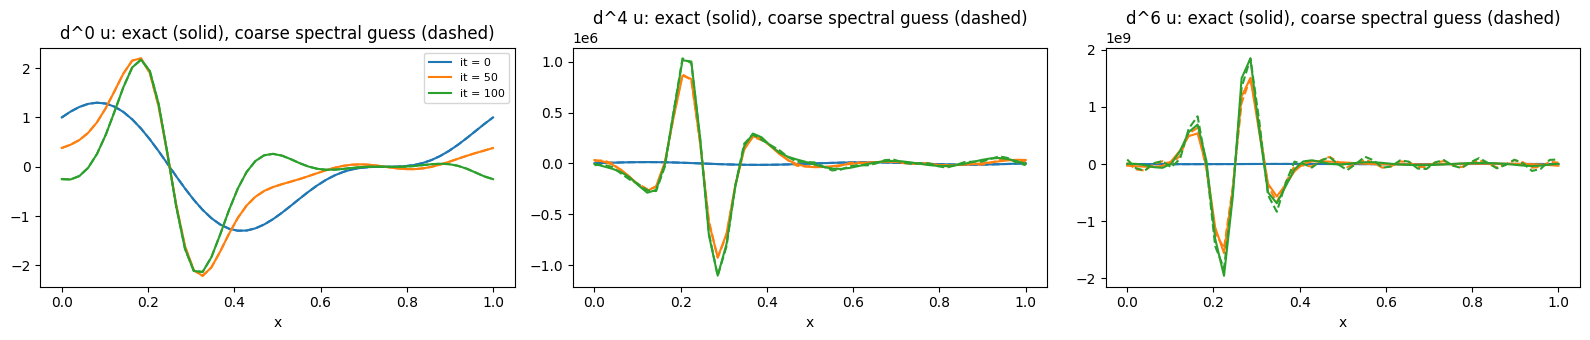

In [22]:
# ── Reference guess (REFERENCE only: pass 1 replaces it): a coarse spectral ETDRK4 solve, what people use for KS ──
#   N_C Fourier modes (K_COARSE times fewer than our nx), time step K_COARSE * dt; derivatives d^0..d^8 u are exact
#   derivatives of the coarse Fourier series, evaluated at our x; linear in t between coarse steps.
#   cost: N_C points per coarse step up to t*
K_COARSE = 2                                                                      # 3 (16 modes) too coarse for L = 22, 4 blows up

def make_guess(K):
    """GUESS[k, it, ix] (k-th x-derivative at grid point (ix, it)), points per coarse step, coarse step."""
    Nc  = 2 * int(round((nx - 1) / K / 2))                                        # even number of modes
    tau = K * dt
    Vc  = ks_etdrk4(Nc, tau, T)                                                   # (coarse steps + 1, Nc)
    k   = 2 * np.pi * np.fft.fftfreq(Nc, 1.0 / Nc); k[Nc // 2] = 0.0              # wavenumbers in x in [0, 1]
    E   = np.exp(1j * np.outer(x_grid, k)) / Nc                                   # (nx, Nc)
    Dc  = np.array([np.real(E @ ((1j * k)[:, None]**n * Vc.T)).T for n in range(N_D)])   # (N_D, coarse steps + 1, nx)
    tg  = np.arange(nt) * dt
    jj  = np.minimum((tg // tau + 1e-9).astype(int), len(Vc) - 2)
    f   = ((tg - jj * tau) / tau)[None, :, None]
    return (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1], Nc, tau

GUESS, N_C, tau = make_guess(K_COARSE)
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                     # (u, u_x, ..., d^8 u) at q
guess_cost   = lambda z: N_C * (int(z[1] * dt / tau) + 1)                         # coarse points up to t*

# ── Check: guessed derivatives vs exact (reference) at 300 random points (reference ONLY here) ──
print(f"guess: {N_C} modes, step {tau:.2f} | cost up to t* = 2.5: {guess_cost((25, int(2.5 / dt)))} points")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(N_WALL, nx - N_WALL)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([ref_derivs(q[0] * dx, q[1] * dt) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex).mean(0) + 1e-12)                              # error relative to the typical size of each derivative
print("median error / typical size, d^0 .. d^8 u: " + "  ".join(f"{v:.3f}" for v in np.median(rel, axis=0)))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for i, it in enumerate([0, nt // 4, nt // 2]):
    ex_ = np.array([ref_derivs(xx, it * dt) for xx in x_grid])
    for ax, k in zip(axes, [0, 4, 6]):
        ax.plot(x_grid, ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
for ax, k in zip(axes, [0, 4, 6]):
    ax.set_title(f"d^{k} u: exact (solid), coarse spectral guess (dashed)"); ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

z* = (25, 50): pass 1 = 111 points (0 without admissible weights) | spectral guess up to t* = 624 points
   pass 1   median error / typical size, d^0 .. d^6 u: 0.014  0.037  0.080  0.116  0.108  0.096  0.072
   spectral median error / typical size, d^0 .. d^6 u: 0.000  0.000  0.001  0.002  0.009  0.013  0.031
z* = (25, 100): pass 1 = 231 points (0 without admissible weights) | spectral guess up to t* = 1224 points
   pass 1   median error / typical size, d^0 .. d^6 u: 0.064  0.122  0.135  0.150  0.115  0.115  0.063
   spectral median error / typical size, d^0 .. d^6 u: 0.000  0.001  0.008  0.018  0.057  0.106  0.245

gate at (25, 100): true local error of the lowest-score stencil (geo mean, 20 points): pass 1 2.56e-03 | spectral 7.27e-04 | exact derivatives 3.88e-04 | typical admissible 5.38e-03


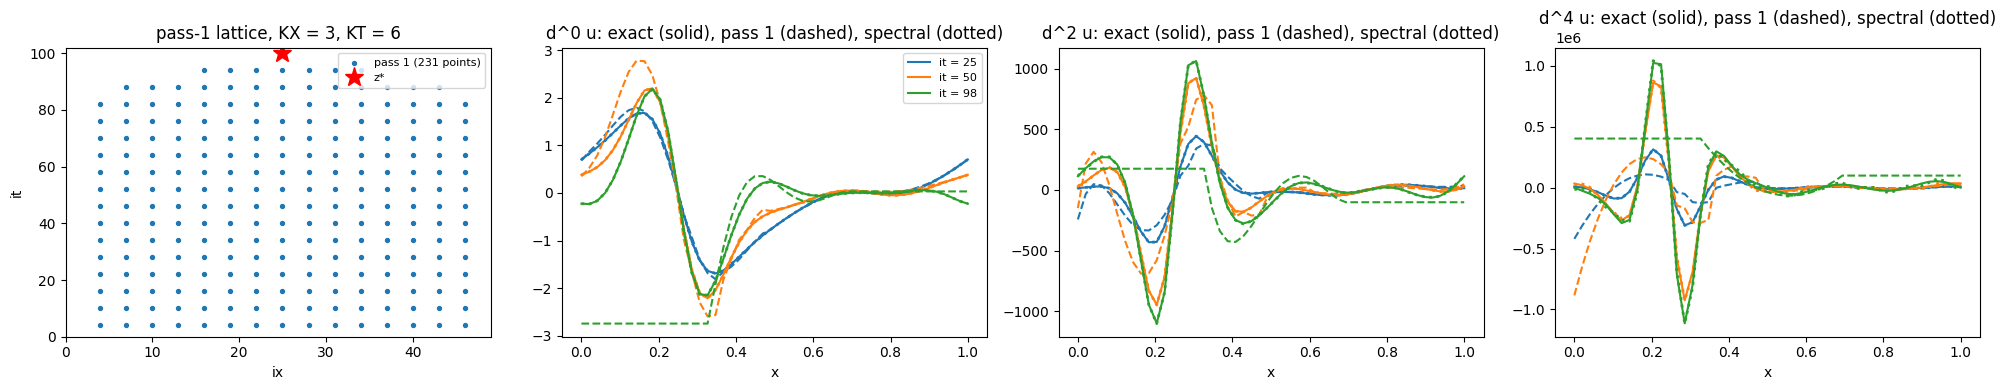

In [23]:
# ── Pass 1: a coarse UNIFORM backward map of z*, used ONLY for the guess (its values never enter u_hat(z*)) ──
#   lattice: every KX-th column and KT-th level, rooted at z*; each lattice point uses the 7 lattice points one coarse
#   level below (offsets -3..3 coarse columns), clamped onto the walls / IC (known data), plus the wall columns at every
#   fine level in between when near a wall. Weights: our Taylor weights (N_ROWS rows), speed C1 u from the value right
#   below, then Picard re-solves with the new value (KS is nonlinear, like Burgers).
#   If N_ROWS rows have no admissible weights, fall back to 3 rows (lower order is fine: it is a guess point only).
#   KX, KT = 3, 6: the sparsest lattice that still guides the score as well as 2x2 (sweep at (25, 100): 231 vs 1,098 points)
#   derivatives: on each lattice level, a local degree-6 polynomial (least squares through the 9 nearest points) -> u..d^6 u
from math import factorial
KX, KT, P1_PICARD = 3, 6, 2
P1_OFF = (-3, -2, -1, 0, 1, 2, 3)
P1_FAIL, FB = [0], [0]                                           # no admissible weights at all (kept the value below) / 3-row fallbacks
is_known_ks = lambda q: q[1] == 0 or q[0] < N_WALL or q[0] > nx - 1 - N_WALL

def p1_nbs(p):
    """Pass-1 neighbours of lattice point p (see above)."""
    clamp = lambda q: (min(max(q[0], 0), nx - 1), max(q[1], 0))
    nbs = [clamp((p[0] + d * KX, p[1] - KT)) for d in P1_OFF]
    reach = max(abs(d) for d in P1_OFF) * KX
    for walls in (range(N_WALL), range(nx - N_WALL, nx)):
        for wcol in walls:
            if abs(p[0] - wcol) <= reach:
                nbs += [(wcol, p[1] - k) for k in range(1, KT) if p[1] - k > 0]
    return list(dict.fromkeys(nbs))

def pass1(z):
    """Values of z*'s coarse backward map {(ix, it): u} (lattice points only, known data excluded)."""
    pts, todo = set(), [z]                                       # backward: the lattice points z* needs
    while todo:
        p = todo.pop()
        if p not in pts and not is_known_ks(p):
            pts.add(p); todo += p1_nbs(p)
    val = {}
    get = lambda q: Ug(q) if is_known_ks(q) else val[q]
    for p in sorted(pts, key=lambda p: p[1]):                    # forward: bottom-up
        nbs = p1_nbs(p)
        v   = np.array([get(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        u_p, ok = get((p[0], max(p[1] - KT, 0))), False          # first speed: the value right below
        for _ in range(1 + P1_PICARD):
            w = solve_weights(DX, DT, C1 * u_p)
            if w is None:
                w = solve_weights(DX, DT, C1 * u_p, rows=3)      # fallback: 3 rows
                FB[0] += w is not None
            if w is None:
                break
            u_p, ok = w @ v, True
        P1_FAIL[0] += not ok
        val[p] = u_p
    return val

get_val = lambda q, val: Ug(q) if is_known_ks(q) else val[q]

def guess_pass1(z):
    """GUESS[k, it, ix] (k-th x-derivative, k = 0..N_D-1; 7, 8 left at 0) for it <= it*, and pass 1's point count."""
    val = pass1(z)
    rows = {0: (np.arange(nx) * dx, u0(np.arange(nx) * dx))}     # the IC level: known everywhere
    for it in {q[1] for q in val if q[1] < z[1]}:
        qs = sorted(q for q in val if q[1] == it)
        walls = [(c, it) for c in list(range(N_WALL)) + list(range(nx - N_WALL, nx))
                 if min(abs(c - q[0]) for q in qs) <= 2 * KX]      # wall columns this level reaches
        qs = sorted(qs + walls)
        rows[it] = (np.array([q[0] for q in qs]) * dx, np.array([get_val(q, val) for q in qs]))
    D = {}
    for it, (xs, us) in rows.items():
        D[it] = np.zeros((N_D, nx))
        for ix in range(nx):
            x    = min(max(ix * dx, xs[0]), xs[-1])
            near = np.argsort(np.abs(xs - x))[:9]
            c    = np.polynomial.polynomial.polyfit(xs[near] - x, us[near], min(6, len(near) - 1))   # c[k] = u^(k)(x) / k!
            D[it][:len(c), ix] = c * [factorial(k) for k in range(len(c))]
    L = sorted(D)
    G = np.zeros((N_D, z[1] + 1, nx))
    for it in range(z[1] + 1):
        if it >= L[-1]:
            G[:, it] = D[L[-1]]
        else:
            lo = max(l for l in L if l <= it); hi = min(l for l in L if l > it)
            f  = (it - lo) / (hi - lo)
            G[:, it] = (1 - f) * D[lo] + f * D[hi]
    return G, len(val)

# ── Check 1: pass-1 derivatives vs the spectral reference guess (GUESS, cell above), in z*'s cone (reference ONLY here) ──
Z_CHECK = [(25, 50), (25, 100)]                                  # t* = 2.5 and 5
P1 = {}
for z in Z_CHECK:
    P1_FAIL[0] = 0
    G1, n1 = guess_pass1(z)
    P1[z] = G1
    cone = [(ix, it) for it in range(1, z[1]) for ix in range(max(N_WALL, z[0] - (z[1] - it)), min(nx - N_WALL, z[0] + z[1] - it + 1))]
    pts  = [cone[i] for i in np.random.default_rng(0).choice(len(cone), 200, replace=False)]
    ex   = np.array([ref_derivs(q[0] * dx, q[1] * dt) for q in pts])
    typ  = np.abs(ex).mean(0) + 1e-12
    rel  = lambda Gs: np.median(np.abs(np.array([Gs[:, q[1], q[0]] for q in pts]) - ex) / typ, axis=0)
    print(f"z* = {z}: pass 1 = {n1} points ({P1_FAIL[0]} without admissible weights) | spectral guess up to t* = {guess_cost(z)} points")
    for name, Gs in [("pass 1", G1), ("spectral", GUESS)]:
        print(f"   {name:8s} median error / typical size, d^0 .. d^6 u: " + "  ".join(f"{v:.3f}" for v in rel(Gs)[:7]))

# ── Check 2 (the gate): which stencil does the score pick with each guess? 20 points in the cone of the larger query.
#    choice by the guessed score; true local error with weights at the true u (what the forward pass's Picard gives) ──
z = Z_CHECK[-1]
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
_cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]
_off = np.array(_cells)[np.array(list(itertools.combinations(range(len(_cells)), 6)))]
cone = [(ix, it) for it in range(3, z[1]) for ix in range(max(N_WALL + 3, z[0] - (z[1] - it)), min(nx - N_WALL - 3, z[0] + z[1] - it + 1))]
res = []
for p in [cone[i] for i in np.random.default_rng(2).choice(len(cone), 20, replace=False)]:
    ut = U(p)
    Wt, okt = solve_weights_many(_off[..., 0] * dx, _off[..., 1] * dt, C1 * ut)
    uv = np.vectorize(lambda a, b: U((p[0] + a, p[1] + b)))(_off[..., 0], _off[..., 1])
    te = np.abs(ut - (Wt * uv).sum(1))
    row = []
    for g in (P1[z][:, p[1], p[0]], GUESS[:, p[1], p[0]], ref_derivs(p[0] * dx, p[1] * dt)):
        W, ok = solve_weights_many(_off[..., 0] * dx, _off[..., 1] * dt, C1 * g[0])
        sc = np.abs((W * sum(c * (_off[..., 0] * dx)**i * (_off[..., 1] * dt)**j for (i, j), c in taylor_coeffs(g, W_DEG).items())).sum(1))
        sc[~(ok & okt)] = np.inf
        row.append(te[np.argmin(sc)])
    res.append(row + [np.median(te[okt])])
res = np.array(res)
gmn = lambda v: float(np.exp(np.mean(np.log(v))))
print("")
print(f"gate at {z}: true local error of the lowest-score stencil (geo mean, 20 points): pass 1 {gmn(res[:, 0]):.2e} | "
      f"spectral {gmn(res[:, 1]):.2e} | exact derivatives {gmn(res[:, 2]):.2e} | typical admissible {gmn(res[:, 3]):.2e}")

# ── Picture: pass-1 lattice of the larger query; exact vs pass 1 vs spectral for u, d^2 u, d^4 u on three levels ──
val = pass1(z)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].scatter([q[0] for q in val], [q[1] for q in val], s=8, c="tab:blue", label=f"pass 1 ({len(val)} points)")
axes[0].plot(*z, "r*", ms=14, label="z*"); axes[0].set_xlim(0, nx - 1); axes[0].set_ylim(0, z[1] + 2)
axes[0].set_xlabel("ix"); axes[0].set_ylabel("it"); axes[0].legend(fontsize=8); axes[0].set_title(f"pass-1 lattice, KX = {KX}, KT = {KT}")
for i, it in enumerate([z[1] // 4, z[1] // 2, z[1] - 2]):
    ex_ = np.array([ref_derivs(xx, it * dt) for xx in x_grid])
    for ax, k in zip(axes[1:], [0, 2, 4]):
        ax.plot(x_grid, ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, P1[z][k, it], "--", color=f"C{i}")
        ax.plot(x_grid, GUESS[k, it], ":", color=f"C{i}", lw=2)
for ax, k in zip(axes[1:], [0, 2, 4]):
    ax.set_title(f"d^{k} u: exact (solid), pass 1 (dashed), spectral (dotted)"); ax.set_xlabel("x")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### Backward map, influence β, forward pass
**Map.** Start at $z^*$ and give it a stencil; every neighbour that is not known data (IC or wall) becomes a pending point. Points are expanded **latest $t$ first**, until every branch ends on the IC or a wall.
**Weights** use $p$'s guessed speed, rounded to 0.02 so they can be cached by (shape, speed).
**Influence.** $\beta_{z^*}=1$; when $p$ is expanded, $\beta_q \mathrel{+}= \beta_p w_q$. All users of $p$ are on higher levels, so $\beta_p$ is final when $p$ is expanded.
**Forward pass.** Values bottom-up, $\hat u_p=\sum_q w_q\hat u_q$; each point re-solves its weights with the speed of its own value (3 Picard steps), so no guessed value enters $\hat u$.
**Identity.** With $\delta_p=u_p-\sum_q w_qu_q$: $\;e(z^*)=\sum_p\beta_p\delta_p$, exact. Check with the Lax–Wendroff stencil everywhere.

In [24]:
# ── Known data: IC and the walls, 2 columns thick (KS is 4th order); exact values there (from the reference) ──
is_known    = lambda q: q[1] == 0 or q[0] < N_WALL or q[0] > nx - 1 - N_WALL
known_value = Ug
PICARD = 1                                       # forward pass: weights re-solved with the speed of the computed value (nonlinear)

# ── Speed at p for its weights: C1 u, u from the guess rounded to U_STEP so weights can be cached by (shape, u) ──
U_STEP  = 0.02
u_build = lambda p: U_STEP * round(float(guess_derivs(p)[0]) / U_STEP)
a_build = lambda p: C1 * u_build(p)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs with p's guessed speed; None if not admissible. Cached by (shape, speed);
    solved with the neighbours sorted, so the result does not depend on the order they were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]
    return w

score_derivs = lambda p: (u_build(p),) + tuple(guess_derivs(p)[1:])   # u = the rounded u the weights use: score and weights agree

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p (u = p's rounded u)."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, score_derivs(p))

# ── The map, built backward from z*: pending points expanded latest t first ──
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}, "stopped": set()}
def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def pending_points(m):
    return [(ix, -it) for it, ix in m["pending"]]

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down. Returns (p, w)."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if not is_known(q):
            if q not in m["beta"]:
                m["beta"][q] = 0.0
                heapq.heappush(m["pending"], (-q[1], q[0]))
            m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p, or None to stop p (stops cell)."""
    m = start_map(z_star)
    while m["pending"]:
        nbs = choose(m, next_point(m))
        stop_point(m) if nbs is None else expand(m, nbs)
    return m

# ── Forward pass: values bottom-up; each point re-solves its weights with the speed of its own value (Picard) ──
def evaluate(m, picard=PICARD):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, C1 * (w @ v))         # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat
# ── Reference map: one fixed stencil, every 2nd column one level down (REF5, a 5-point explicit scheme on a 2dx grid),
#    clamped onto the walls / IC. Next to a wall (ix = 2, nx - 3) the clamped copy is not admissible, so there REF_WALL
#    (mirrored on the right), which also uses the wall values at its own level (known data).
#    Why REF5: compact 2-level stencils (e.g. offsets -3..3 over 2 levels) are admissible but unstable (they grow up to
#    1.6x per step; KS itself grows at most 1.013x). REF5 grows 1.014x per step and is admissible for every u in [-3, 3] ──
REF5     = [(-4, -1), (-2, -1), (0, -1), (2, -1), (4, -1)]
REF_WALL = [(0, -1), (1, -1), (2, -1), (4, -1), (-2, 0), (-1, 0)]

def ref_offsets(p):
    """Offsets of p's reference stencil (the left-wall shape mirrored at the right wall)."""
    if p[0] == N_WALL:
        return REF_WALL
    if p[0] == nx - 1 - N_WALL:
        return [(-d, k) for d, k in REF_WALL]
    return REF5

wide = lambda m, p: list(dict.fromkeys((min(max(p[0] + d, 0), nx - 1), max(p[1] + k, 0)) for d, k in ref_offsets(p)))

### Menu, admissible stencils, mask, report
**Menu (a rule, no greedy).** Every 6-point shape within $|\Delta i_x|\le4$, 1–3 levels below $p$, that is admissible for every $u\in[-3,3]$ and stable when used everywhere (growth per step $\le1.02$; KS itself grows at most $e^{\Delta t/4}\approx1.013$). Plus the wide rows (every 3rd column) and one wall shape per side that uses the wall values at $p$'s own level.
**Admissible at $p$:** the menu shapes whose cells land on distinct points and whose weights pass the test with $p$'s guessed speed; cached by local situation and speed, with each shape's moments for the score.
**Lowest score:** every point takes its lowest-score shape (a rule, no RL). **Report:** points, true error at $z^*$, exact bound $\sum_p|\beta_p\delta_p|$ (exact solution for reporting only).

menu: 2160 window shapes (of 296,010) + 16 wide rows + 2 wall shapes = 2178 shapes on 65 cells  (51 s)
admissible shapes per point: min 1, median 2176, max 2176 | points with none: 0
z* = (25, 50) reference   : 1935 points, error 6.81e-02, exact bound 8.19e-02  (1 s)
z* = (25, 50) lowest score: 2083 points, error 2.33e-02, exact bound 9.87e-02  (1 s)
z* = (25, 100) reference   : 4235 points, error 2.83e-01, exact bound 4.90e-01  (1 s)
z* = (25, 100) lowest score: 4390 points, error 3.08e-02, exact bound 6.22e-01  (2 s)


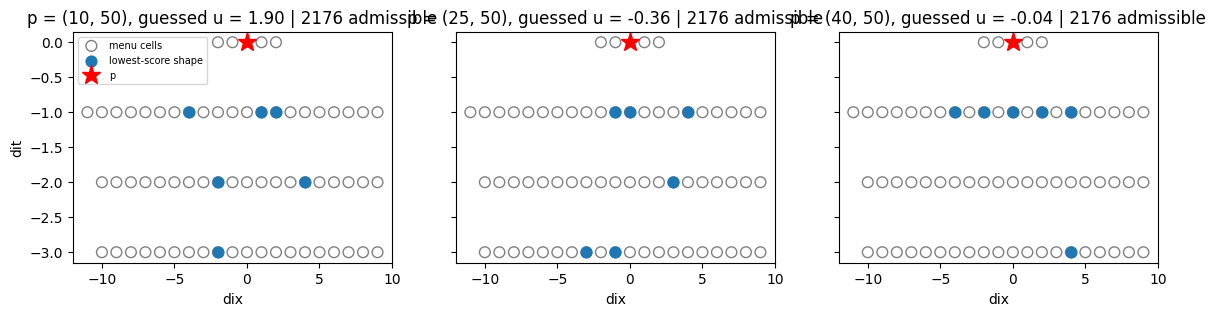

In [25]:
# ── The menu of stencil shapes, by a rule (no greedy): every 6-point shape that is admissible and stable ──
#   window: |dix| <= R_X columns, 1 to K_T levels below p; a shape = 6 of its cells
#   kept if (1) admissible (rank, cond, |w|_1) for every u in U_RANGE (speed C1 u)
#           (2) stable: used everywhere, its growth per time step (largest root of the multistep recurrence, over all
#               wavenumbers) stays <= G_MAX at u = -3, 0, 3 (KS itself grows at most exp(dt / 4) = 1.013 per step)
#   plus: the wide rows (every 3rd column, 1 to K_T levels down, centre shifted by -3..3), same test; they reach
#         past the window and are the stable choice for the stiff u_xxxx term
#   plus: next to each wall, one shape that also uses the wall values at p's own level (known data); without it the
#         point next to the wall at it = 1 has no admissible stencil
R_X, K_T, G_MAX = 4, 3, 1.02
U_RANGE = np.linspace(-3, 3, 7)
N_NB    = 6                                                       # neighbours per stencil (N_ROWS + 1)
TERMS   = list(taylor_coeffs((0.0,) * N_D))                       # the (i, j) Taylor terms of the score

def growth(O, W):
    """Largest growth per time step of shapes O (M, n, 2) with weights W (M, n), used everywhere, over all wavenumbers."""
    lv, g = int(-O[..., 1].min()), np.zeros(len(O))
    for th in np.linspace(0, np.pi, 61):
        e = W * np.exp(1j * th * O[..., 0])
        a = np.stack([(e * (O[..., 1] == -k)).sum(1) for k in range(1, lv + 1)], 1)   # u^n = sum_k a_k u^(n-k)
        C = np.zeros((len(O), lv, lv), complex); C[:, 0] = a
        C[:, np.arange(1, lv), np.arange(lv - 1)] = 1                 # companion matrix
        g = np.maximum(g, np.abs(np.linalg.eigvals(C)).max(1))
    return g

def keep(O):
    """Admissible for every u in U_RANGE and stable."""
    ok = np.ones(len(O), bool)
    for u in U_RANGE:
        ok &= solve_weights_many(O[..., 0] * dx, O[..., 1] * dt, C1 * u)[1]
    O, g = O[ok], np.zeros(ok.sum())
    for u in (-3.0, 0.0, 3.0):
        g = np.maximum(g, growth(O, solve_weights_many(O[..., 0] * dx, O[..., 1] * dt, C1 * u)[0]))
    return [tuple(map(tuple, o)) for o in O[g <= G_MAX]]

t0 = time.time()
_cells = [(d, -k) for k in range(1, K_T + 1) for d in range(-R_X, R_X + 1)]
_all   = np.array(_cells)[np.array(list(itertools.combinations(range(len(_cells)), N_NB)))]   # (M, 6, 2)
SHAPES = [s for i in range(0, len(_all), 100_000) for s in keep(_all[i:i + 100_000])]
n_win  = len(SHAPES)
_rows  = np.array([[(s + 3 * j, -k) for j in range(-3, 3)] for k in range(1, K_T + 1) for s in range(-3, 4)])
SHAPES += keep(_rows)
REF_WALL = ((0, -1), (1, -1), (2, -1), (4, -1), (-2, 0), (-1, 0))  # next to the left wall; mirrored on the right
SHAPES += [REF_WALL, tuple((-d, k) for d, k in REF_WALL)]
SHAPES = list(dict.fromkeys(tuple(sorted(s)) for s in SHAPES))

# ── The window = every cell some shape uses; a shape = a tuple of window cells (what the env and greedy use) ──
WINDOW  = sorted({c for s in SHAPES for c in s}, key=lambda c: (-c[1], c[0]))
N_CELLS = len(WINDOW)
_idx    = {c: k for k, c in enumerate(WINDOW)}
MENU    = [tuple(sorted(_idx[c] for c in s)) for s in SHAPES]
print(f"menu: {n_win} window shapes (of {len(_all):,}) + {len(SHAPES) - n_win - 2} wide rows + 2 wall shapes = "
      f"{len(MENU)} shapes on {N_CELLS} cells  ({time.time() - t0:.0f} s)")

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── The menu shapes admissible at p: cached by local situation and guessed speed (shapes, cell usage, moments) ──
#   a shape is out at p if two of its cells land on the same point (walls / IC) or it uses p's own level off the walls
_sets_cache = {}
REACH = max(abs(c[0]) for c in WINDOW) + 1
def admissible(p):
    """(admissible menu shapes as tuples of cells, cell-usage matrix, scores at p)."""
    key = (min(p[0], REACH), min(nx - 1 - p[0], REACH), min(p[1], K_T + 1), a_build(p))
    if key not in _sets_cache:
        cand = []
        for s in MENU:
            pts = [place(p, k) for k in s]
            if len(set(pts)) == len(pts) and all(q[1] < p[1] or is_known(q) for q in pts):
                cand.append(s)
        off = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in cand])   # (M, 6, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))
        sets   = [s for s, o in zip(cand, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(score_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible shape contains the picks so far plus k (cell-by-cell mode)."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map, with the weights the forward pass used (u_true ONLY here) ──
def report(m, picard=PICARD):
    """Points, true error at z*, exact bound sum |beta delta| (beta recomputed with the weights actually used)."""
    z = m["z_star"]
    u_hat, W = evaluate(m, picard), m["w_used"]
    beta = {z: 1.0}
    for p in sorted(m["stencil"], key=lambda p: -p[1]):           # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}

# ── Check 1: every point below the largest check query has at least one admissible shape ──
z_big = (25, 100)
counts = np.array([[len(admissible((ix, it))[0]) for ix in range(N_WALL, nx - N_WALL)] for it in range(1, z_big[1] + 1)])
print(f"admissible shapes per point: min {counts.min()}, median {int(np.median(counts))}, max {counts.max()} | "
      f"points with none: {(counts == 0).sum()}")

# ── Check 2: reference vs lowest score (each point its lowest-score shape, no RL) ──
for z in [(25, 50), (25, 100)]:
    for name, rule in [("reference", wide), ("lowest score", lowest_score)]:
        t0 = time.time()
        rep = report(build_map(z, rule))
        print(f"z* = {z} {name:12s}: {rep['points']} points, error {rep['error']:.2e}, "
              f"exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the menu's cells, and the lowest-score shape at three points ──
fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, p in zip(axes, [(10, 50), (25, 50), (40, 50)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=60, facecolors='none', edgecolors='gray', label='menu cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=60, color='tab:blue', label='lowest-score shape')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed u = {u_build(p):.2f} | {len(sets)} admissible"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

In [16]:
print(W_DEG, N_D, guess_derivs.__code__.co_names)

8 9 ('GUESS',)


### Greedy and the cost of each rule
**Greedy**: at every point, the admissible stencil with the best one-step reward, $\;|\beta_p|s_p/\mathrm{EPS}+\lambda\,(\text{new points})/N_{\rm LW}$.
**Cost** of a map: points, and weight systems solved — for the stencil library (all candidates, once per local situation and speed, shared by every query), while building, and in the forward pass (1 Picard step per point). Cold = empty library, warm = library already filled.

In [26]:
# ── Reward units (also used by the environment) ──
EPS = 1e-3                                                        # accuracy unit
def n_lw(z):
    """Points unit: size of z*'s full cone (one more column each side per level, walls excluded)."""
    return sum(min(nx - 1 - N_WALL, z[0] + j) - max(N_WALL, z[0] - j) + 1 for j in range(z[1]))

def greedy_rule(lam):
    """At every point the admissible shape with the best one-step reward (beta_p is final when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

# ── Cost of each rule at z*: points, weight solves (build, forward), time; library cold or warm ──
def cost_run(z, rule, cold):
    if cold:
        _sets_cache.clear(); _w_cache.clear()
    n0, t0 = N_SOLVES[0], time.time()
    m = build_map(z, rule)
    n_build, t_build = N_SOLVES[0] - n0, time.time() - t0
    rep = report(m)                                               # the forward pass (PICARD steps) happens here
    return rep | {"solves_build": n_build, "solves_fwd": N_SOLVES[0] - n0 - n_build, "time": t_build}

for z in [(25, 50), (25, 100)]:
    print(f"z* = {z}, full cone {n_lw(z)} points")
    print(f"{'rule':14s} {'library':8s} {'points':>7s} {'error':>9s} {'bound':>9s} {'solves build':>13s} {'solves fwd':>11s} {'build time':>11s}")
    for name, rule in [("reference", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
        for cold in (True, False):
            r = cost_run(z, rule, cold)
            print(f"{name:14s} {'cold' if cold else 'warm':8s} {r['points']:7d} {r['error']:9.2e} {r['bound']:9.2e} "
                  f"{r['solves_build']:13,d} {r['solves_fwd']:11,d} {r['time']:10.1f}s")

# ── How many Picard steps are needed? error and exact bound vs steps, same maps (0 = the build weights) ──
z = (25, 50)
for name, rule in [("reference", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
    m = build_map(z, rule)
    reps = {k: report(m, picard=k) for k in (0, 1, 2, 3)}
    print(f"{name:14s} | " + "  ".join(f"{k}: err {r['error']:.2e} bnd {r['bound']:.2e}" for k, r in reps.items()))

z* = (25, 50), full cone 1771 points
rule           library   points     error     bound  solves build  solves fwd  build time
reference      cold        1935  6.81e-02  8.19e-02           289       1,935        0.1s
reference      warm        1935  6.81e-02  8.19e-02             0       1,935        0.0s
lowest score   cold        2083  2.33e-02  9.87e-02     1,235,437       2,083       26.0s
lowest score   warm        2083  2.33e-02  9.87e-02             0       2,083        0.1s
greedy lam=1   cold        1816  2.60e-02  9.44e-02     1,100,201       1,816       23.6s
greedy lam=1   warm        1816  2.60e-02  9.44e-02             0       1,816        0.3s
z* = (25, 100), full cone 4071 points
rule           library   points     error     bound  solves build  solves fwd  build time
reference      cold        4235  2.83e-01  4.90e-01           423       4,235        0.2s
reference      warm        4235  2.83e-01  4.90e-01             0       4,235        0.0s
lowest score   cold      

In [27]:
# ── From here on the guess is PASS 1 (KX x KT lattice of the pass-1 cell), not the spectral reference: built once per
#    query, made active before a map is built ──
#   every function reads the guess through guess_derivs; the active guess sits in a dict (mutated, never rebound),
#   so the training processes see the change too. (KS: the guess gives the speed C1 u of the weights AND feeds the score)
_ACTIVE, _P1 = {"G": None}, {}
guess_derivs = lambda q: _ACTIVE["G"][:, q[1], q[0]]             # (u, u_x, ..., d^6 u, 0, 0) at q

def use_guess(z):
    """Make z*'s pass-1 guess the active one. Returns pass 1's points (added to every map method's cost)."""
    if z not in _P1:
        _P1[z] = guess_pass1(z)
    _ACTIVE["G"] = _P1[z][0]
    return _P1[z][1]

_build_map = build_map
def build_map(z_star, choose):
    """Same as before, with z*'s own pass-1 guess made active first (every rule-built map goes through here)."""
    use_guess(z_star)
    return _build_map(z_star, choose)

# ── Check: greedy on the pass-1 guess at the training queries; the accuracy term sum |beta| s sets the EPS scale ──
for z in [(25, 30), (15, 40), (35, 40), (25, 50), (25, 80)]:
    n1 = use_guess(z)
    m  = build_map(z, greedy_rule(1.0))
    B  = sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])
    r  = report(m)
    print(f"z* = {z}: pass 1 {n1} points | greedy {r['points']} points (cone {n_lw(z)}), estimated sum|beta|s {B:.2e}, "
          f"error {r['error']:.2e}, bound {r['bound']:.2e}")

z* = (25, 30): pass 1 51 points | greedy 860 points (cone 851), estimated sum|beta|s 5.09e-04, error 2.14e-02, bound 3.05e-02
z* = (15, 40): pass 1 78 points | greedy 1327 points (cone 1221), estimated sum|beta|s 2.32e-03, error 2.22e-02, bound 4.88e-01
z* = (35, 40): pass 1 81 points | greedy 1215 points (cone 1201), estimated sum|beta|s 3.85e-04, error 1.56e-02, bound 2.48e-02
z* = (25, 50): pass 1 111 points | greedy 1735 points (cone 1771), estimated sum|beta|s 7.56e-04, error 8.73e-02, bound 1.43e-01
z* = (25, 80): pass 1 186 points | greedy 3122 points (cone 3151), estimated sum|beta|s 1.69e-03, error 2.08e-01, bound 4.28e-01


### Environment
**Episode.** Build one map for $z^*$. Each step the agent picks one window cell for the current point, or **STOP** (only with `stops=True`, before its first pick, never at $z^*$, only if a stop stencil exists). After 5 picks the point is expanded.
**Reward.** Accuracy per decision: $-|\beta_p|s_p/\mathrm{EPS}$ (a stencil) or $-|\beta_p|s^{\rm stop}_p/\mathrm{EPS}$ (a stop). Points cost, `points_cost`:
- `"step"`: $-\lambda\,(\text{new points})/N_{LW}$ at each stencil;
- `"terminal"`: $-\lambda\,N_{\rm total}/N_{LW}$ once at the end (same total as "step");
- `"avg_dt"`: $-\lambda\,(1-\overline{\text{depth}}/3)$ once at the end.

**Shaping** (`shaping`): every reward gets $\Phi(s')-\Phi(s)$; the extra terms add up to $-\Phi(s_0)$, a constant, so the best policy does not change.
- `"lw"`: $\Phi=-\sum_{q\ \rm pending}\big(|\beta_q|A_q/\mathrm{EPS}+\lambda N_q/N_{LW}\big)$, the LW map's cost-to-go;
- `"height"`: $\Phi=-\lambda\hat N/N_{LW}$, $\hat N=\sum_x\max(0,c(x)-1)$, $c(x)=\max_q(t_q-|x-i_q|)$: the points still to create, as the union of the pending points' backward cones.

**State**: per window cell picked / in the map / known data; $\log|\beta_p|$, position, guessed $u,u_x,u_{xx}$, points used and pending, pending influence, $\log\lambda$, whether $p$ can stop and what it would cost, mean stencil depth so far.
Check: one random episode per setting; the rewards must add up to the return formula (with shaping, differ by exactly $-\Phi(s_0)$).

In [28]:
# ── Shaping potentials (estimates only: score, beta, no u_true) ──
#   "lw":     cost-to-go of every point of the reference map of z*  (A_q: estimated error of q's subtree per unit influence,
#             N_q: points of q's subtree, a point shared by several users split between them)
#   "height": points still to create = the union of the pending points' backward cones (one cell per level each side),
#             c(x) = max_q (t_q - |x - i_q|),  N_hat = sum_x max(0, c(x) - 1)
def cost_to_go(m):
    users = {}
    for p, (nbs, w) in m["stencil"].items():
        for q in set(nbs):
            users[q] = users.get(q, 0) + 1
    A, N = {}, {}
    for p in sorted(m["stencil"], key=lambda p: p[1]):            # bottom-up: the points a stencil uses come first
        nbs, w = m["stencil"][p]
        A[p], N[p] = point_score(p, nbs, w), 1.0
        for q, wq in zip(nbs, w):
            if q in A:                                            # an expanded point (not data)
                A[p] += abs(wq) * A[q]
                N[p] += N[q] / users[q]
    return A, N

_ctg_cache = {}
def lw_cost_to_go(z):
    if z not in _ctg_cache:
        _ctg_cache[z] = cost_to_go(build_map(z, wide))
    return _ctg_cache[z]

_xs = np.arange(N_WALL, nx - N_WALL)
def cone_points(pend):
    """Points still to create below the pending points: the union of their backward cones (interior columns)."""
    if not pend:
        return 0.0
    ix, it = np.array(pend).T
    c = (it[None, :] - np.abs(_xs[:, None] - ix[None, :])).max(1)
    return float(np.maximum(0, c - 1).sum())

# ── Environment: one step = one pick, or STOP ──
#   stencil at p : -|beta_p| s_p / EPS      (- lam * new points / N_LW   if points_cost = "step")
#   stop at p    : -|beta_p| s_stop / EPS   (no new points)
#   end          : - lam * total points / N_LW             if points_cost = "terminal"  (same total as "step")
#                  - lam * (1 - mean stencil depth / K_T)   if points_cost = "avg_dt"
#   shaping      : + Phi(s') - Phi(s) on every reward; the extra terms add up to -Phi(start), a constant of the query
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
STOP    = N_CELLS                                                 # the extra action
N_OBS   = 3 * N_CELLS + 15

# ── Menu (switch menu=MENU): one action = one whole stencil shape from the rule-built MENU of the window cell ──
#   State adds each shape's new points (bookkeeping, no Taylor score). A point where no menu shape is admissible
#   gets its lowest-score stencil without a decision (like the forced points).
Z_MULTI = [(25, 50), (15, 40), (35, 40), (25, 30)]                # training queries (best.zip selected on (25, 50))
MENU_USES = np.zeros((len(MENU), N_CELLS))                       # MENU_USES[i, k] = 1 if shape i uses window cell k
for i, c in enumerate(MENU):
    MENU_USES[i, list(c)] = 1
_menu_ok = {}
def menu_ok(p):
    """Which menu shapes are admissible at p (cached with p's admissible list)."""
    sets = admissible(p)[0]
    if id(sets) not in _menu_ok:
        have = set(sets)
        _menu_ok[id(sets)] = (sets, np.array([c in have for c in MENU]))
    return _menu_ok[id(sets)][1]
print(f"menu: {len(MENU)} shapes | training queries {Z_MULTI}")

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(1.0, 1.0), cap=3.0, stops=False, shaping=None, points_cost="step", menu=None):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.stops, self.shaping, self.points_cost, self.menu = stops, shaping, points_cost, menu
        self.n_obs = N_OBS + (len(menu) if menu else 0)
        self.stop_a = len(menu) if menu else STOP                   # index of the STOP action
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(self.n_obs,), dtype=np.float32)
        self.action_space = spaces.Discrete(self.stop_a + 1)        # one window cell (or one menu shape), or STOP

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.guess_points = use_guess(self.z)                      # pass-1 guess of this query
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B, self.depths = start_map(self.z), [], 0.0, []
        self.phi0 = self.phi = self._phi()
        self.carry = self._play_forced()                          # forced points before the first decision: paid at step 1
        return self._obs(), {}

    def _phi(self):
        """Shaping potential: minus the estimated cost of finishing the pending points (0 without shaping)."""
        pend = pending_points(self.m)
        if self.shaping == "lw":
            A, N = lw_cost_to_go(self.z)
            return -sum(abs(self.m["beta"][q]) * A.get(q, 0.0) / EPS + self.lam * N.get(q, 1.0) / self.N_ref for q in pend)
        if self.shaping == "height":
            return -self.lam * cone_points(pend) / self.N_ref
        return 0.0

    def _complete(self, cells):
        """Expand the next point with these cells: its accuracy now (beta_p is final), and its new points if per step."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        acc = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += acc
        self.depths.append(np.mean([p[1] - q[1] for q in nbs]))
        return -acc / EPS - (self.lam * n_new / self.N_ref if self.points_cost == "step" else 0.0)

    def _stop(self):
        """Stop the next point: its value from existing points; its accuracy now, no new points."""
        p = next_point(self.m)
        acc = abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2]
        stop_point(self.m)
        self.B += acc
        return -acc / EPS

    def _play_forced(self):
        """Points with only one admissible stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            p = next_point(self.m)
            sets, _, sc = admissible(p)
            if len(sets) == 1:
                r += self._complete(sets[0])
            elif self.menu and not menu_ok(p).any():                # no menu shape fits: lowest score, no decision
                r += self._complete(sets[int(np.argmin(sc))])
            else:
                break
        return r

    def _can_stop(self, p):
        return self.stops and not self.picks and p != self.z and reuse_stencil(self.m, p) is not None

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(self.n_obs, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = pending_points(self.m)
        d      = guess_derivs(p)
        can    = self._can_stop(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam),                                # price of a point
                float(can),                                        # can p stop now?
                np.log10(abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2] / EPS + 1e-12) if can else 0.0,   # cost of stopping p now
                np.mean(self.depths) / K_T if self.depths else 0.0]   # mean stencil depth so far (levels / K_T)
        new = [MENU_USES @ (~exists & ~known) / N_NB] if self.menu else []   # each menu shape's new points (/ N_NB)
        return np.concatenate([picked, exists, known, glob, *new]).astype(np.float32)

    def step(self, k):
        r, self.carry = self.carry, 0.0
        if k == self.stop_a:
            r += self._stop()
        elif self.menu:
            r += self._complete(self.menu[k])
        else:
            self.picks.append(int(k))
            if len(self.picks) < len(admissible(next_point(self.m))[0][0]):    # still choosing p's stencil
                return self._obs(), r, False, False, {}
            r += self._complete(self.picks)
            self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            phi = self._phi()
            r, self.phi = r + phi - self.phi, phi
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: every point left unexpanded costs its worst stencil
        for q in pending_points(self.m):
            acc = abs(self.m["beta"][q]) * admissible(q)[2].max()
            self.B += acc
            r -= acc / EPS
        n_points = len(self.m["stencil"]) + len(self.m["pending"]) - 1          # every point but z*
        if self.points_cost == "terminal":
            r -= self.lam * n_points / self.N_ref
        elif self.points_cost == "avg_dt":
            r -= self.lam * (1 - np.mean(self.depths) / K_T)
        r -= self.phi                                              # Phi = 0 at the end
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "stops": len(self.m["stopped"]),
                "lam": self.lam, "score_ratio": self.B / EPS, "points_ratio": n_points / self.N_ref,
                "depth": float(np.mean(self.depths))}
        return np.zeros(self.n_obs, np.float32), r, True, False, info

    def action_masks(self):
        p = next_point(self.m)
        cells = menu_ok(p) if self.menu else pick_mask(p, self.picks)
        return np.r_[cells, self._can_stop(p)]                      # STOP: before the first pick, never at z*, if possible

# ── Check: one random episode at the selection query; the rewards must add up to minus the accuracy and points terms ──
env = MapEnv(queries=[(25, 50)], menu=MENU)
obs, _ = env.reset(seed=0)
rng, ret, done, steps = np.random.default_rng(0), 0.0, False, 0
while not done:
    obs, r, done, _, info = env.step(int(rng.choice(np.flatnonzero(env.action_masks()))))
    ret, steps = ret + r, steps + 1
print(f"random episode: {steps} decisions, {info['points']} points, return {ret:.3f} = "
      f"-{info['score_ratio']:.3f} (accuracy) - {info['points_ratio']:.3f} (points)  -> diff {ret + info['score_ratio'] + info['points_ratio']:.1e}")

menu: 2178 shapes | training queries [(25, 50), (15, 40), (35, 40), (25, 30)]
random episode: 2021 decisions, 2023 points, return -128.456 = -127.314 (accuracy) - 1.142 (points)  -> diff -3.6e-13


### Map figure
One figure for any finished map (baselines, training snapshots, the progress video):
1. the map, coloured by influence $|\beta_p|$ on $z^*$, stopped points marked;
2. the solution at $t^*$: exact $u(x,t^*)$, the computed points of the top levels, and the predicted vs exact value at $z^*$.

The exact solution is used only in this figure.

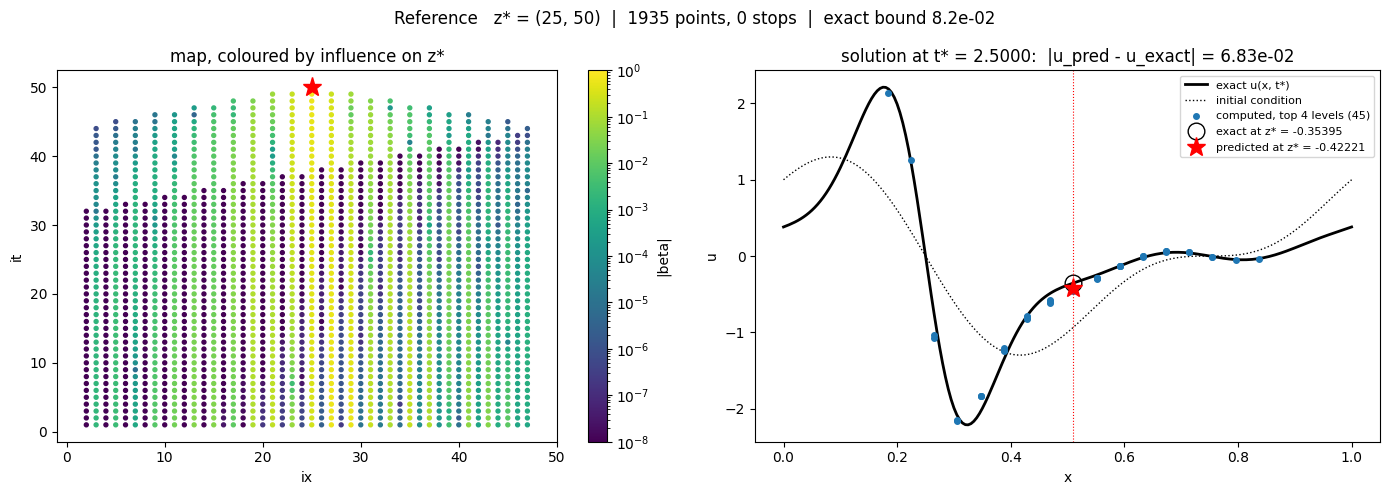

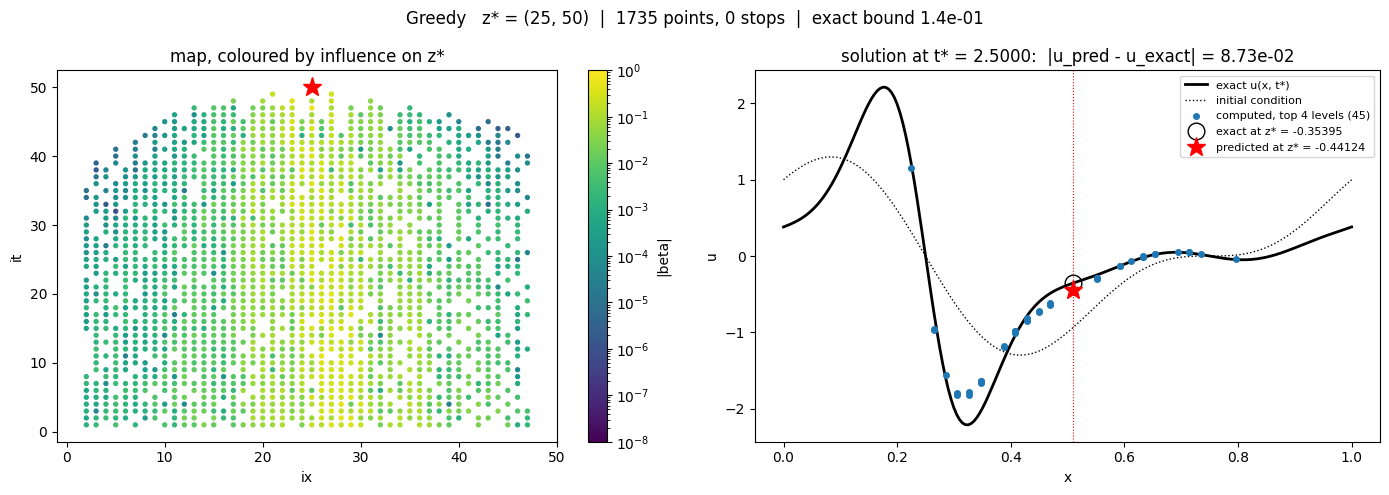

In [29]:
# ── One figure for any finished map (baselines, snapshots, training video) ──
#   left : the map, coloured by influence |beta| on z*; stopped points marked
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    if m["stopped"]:
        S = np.array(list(m["stopped"]))
        a1.plot(S[:, 0], S[:, 1], "x", color="#e34948", ms=4, label=f"stopped ({len(S)})")
        a1.legend(fontsize=8)
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4, label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points, {len(m['stopped'])} stops  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

z = (25, 50)
for name, rule in [("Reference", wide), ("Greedy", greedy_rule(1.0))]:
    plot_map(build_map(z, rule), name)

### Training helpers
- `make_env`: one training environment (action mask + episode monitor); the switches (`stops`, `shaping`, `points_cost`) are passed through.
- `run_policy`: one episode with the policy's most likely picks, **without shaping** (the real return), same switches otherwise.
- `MapLogCallback`: points, accuracy term, stops, mean depth and finish rate of the training episodes (mean of the last 100) → TensorBoard.
- `SnapshotCallback`: every `every` steps, the policy at the training query and at one unseen query (watching only): numbers, map figure, checkpoint. The checkpoint with the best **training-query return** is kept as `best` (no exact solution in the selection); the last model is always reported too.

Check: a tiny run (2 environments, 512 steps, one snapshot).

In [31]:
# ── Training helpers ──
import json

def make_env(queries, seed, **env_kw):
    """One training environment (with the action mask and the episode monitor). env_kw: stops, shaping, points_cost, lam_range."""
    def _init():
        env = Monitor(ActionMasker(MapEnv(queries=queries, **env_kw), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, **env_kw):
    """One episode on z* with the policy's most likely picks, WITHOUT shaping (the real return). Returns the finished env."""
    env = MapEnv(queries=[z], **{**env_kw, "shaping": None})
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        act, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(act)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: numbers of every finished training episode, mean of the last 100, to TensorBoard ──
class MapLogCallback(BaseCallback):
    KEYS = ("points_ratio", "score_ratio", "stops", "depth", "finished")
    def __init__(self):
        super().__init__()
        self.hist = {k: [] for k in self.KEYS}
    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done and "points_ratio" in info:
                for k in self.KEYS:
                    self.hist[k].append(float(info[k]))
                    self.logger.record(f"map/{k}", np.mean(self.hist[k][-100:]))
        return True

# ── Callback 2: every `every` steps, the deterministic policy on the training query and one unseen query ──
#   saves the map figures and a checkpoint; keeps the checkpoint with the best TRAINING-query return as "best"
#   (selection uses estimates only; the unseen query and the true error are for watching, never for selection)
class SnapshotCallback(BaseCallback):
    def __init__(self, every, z_train, z_watch, folder, env_kw):
        super().__init__()
        self.every, self.z_train, self.z_watch, self.folder, self.env_kw = every, z_train, z_watch, folder, env_kw
        self.next, self.best, self.rows = every, -np.inf, []
        os.makedirs(folder, exist_ok=True)
    def _on_step(self):
        if self.num_timesteps < self.next:
            return True
        self.next += self.every
        steps = self.num_timesteps
        self.model.save(os.path.join(self.folder, f"ckpt_{steps}"))
        for z in (self.z_train, self.z_watch):
            env = run_policy(self.model, z, **self.env_kw)
            rep = report(env.m)
            row = {"steps": steps, "z": list(z), "return": env.ret, "points": rep["points"], "stops": env.info["stops"],
                   "depth": env.info["depth"], "error": rep["error"], "bound": rep["bound"]}
            self.rows.append(row)
            tag = "train" if z == self.z_train else "watch"
            for k in ("return", "points", "stops", "depth", "error", "bound"):
                self.logger.record(f"snap_{tag}/{k}", row[k])
            plot_map(env.m, f"{steps:,} steps ({tag})", path=os.path.join(self.folder, f"snap_{tag}_{steps:09d}.png"))
            print(f"{steps:>10,} | {tag} z* = {z}: return {env.ret:7.3f}, {rep['points']} points, {env.info['stops']} stops, "
                  f"depth {env.info['depth']:.2f}, error {rep['error']:.2e}, bound {rep['bound']:.2e}")
            if z == self.z_train and env.ret > self.best:
                self.best = env.ret
                self.model.save(os.path.join(self.folder, "best"))
        with open(os.path.join(self.folder, "snapshots.json"), "w") as f:
            json.dump(self.rows, f)
        return True


In [32]:
# ── Tiny run: 2 environments, 2,048 steps, to check the pipeline and measure the speed ──
KW_TEST = dict(stops=False, shaping=None, points_cost="step", menu=MENU)
vec = SubprocVecEnv([make_env(Z_MULTI, seed=i, **KW_TEST) for i in range(2)])
model = MaskablePPO("MlpPolicy", vec, seed=0, verbose=0, n_steps=512, batch_size=512, gamma=1.0, gae_lambda=1.0)
t0 = time.time()
model.learn(1024)                                                  # warm-up: each process fills its stencil library
t1 = time.time()
model.learn(1024, reset_num_timesteps=False)                       # timed: library mostly warm
t2 = time.time()
vec.close()
print(f"warm-up {t1 - t0:.0f} s | timed: {1024 / (t2 - t1):.0f} steps/s with 2 envs "
      f"-> 10M steps with {8} envs ~ {10e6 / (4 * 1024 / (t2 - t1)) / 3600:.1f} h if it scales with the envs")

warm-up 3 s | timed: 679 steps/s with 2 envs -> 10M steps with 8 envs ~ 1.0 h if it scales with the envs


In [33]:
# ── Training: the menu agent on advection-diffusion (pass-1 guess), MULTI-QUERY, seeds 1, 3, 5, 10M steps each ──
#   trained on the 4 queries of Z_MULTI (env cell); best.zip chosen on Z_TRAIN; Z_WATCH unseen, watched only
#   each run is skipped if its final.zip exists and resumes from its newest checkpoint after a crash
RUN_ROOT = f"runs{date.today():%m-%d}"
Z_TRAIN, Z_WATCH = (25, 50), (25, 80)
SEEDS, STEPS, EVERY, N_ENVS = (1, 3, 5), 10_000_000, 100_000, 8
PPO_KW = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=1.0, learning_rate=3e-4, ent_coef=0.0)
KW = dict(stops=False, shaping=None, points_cost="step", menu=MENU)
seed_dir = lambda name, z, seed: os.path.join(RUN_ROOT, f"nb17_ks_{name}_z{z[0]}-{z[1]}_eps{EPS:.0e}_seed{seed}_pass1")

def train(name, queries, z_select, kw, seed, steps):
    """One training run on `queries`; snapshots (and best.zip) on z_select and Z_WATCH."""
    folder = seed_dir(name, z_select, seed)
    if os.path.exists(os.path.join(folder, "final.zip")):
        print(f"{name} seed {seed}: already done, skipped", flush=True); return
    vec = SubprocVecEnv([make_env(queries, seed=seed * 100 + i, **kw) for i in range(N_ENVS)])
    snap = SnapshotCallback(EVERY, z_select, Z_WATCH, folder, kw)
    ckpts = [f for f in os.listdir(folder) if f.startswith("ckpt_")] if os.path.isdir(folder) else []
    if ckpts:                                                          # resume after a crash
        model = MaskablePPO.load(os.path.join(folder, max(ckpts, key=lambda f: int(f[5:-4]))), env=vec, tensorboard_log=RUN_ROOT)
        snap.rows = json.load(open(os.path.join(folder, "snapshots.json")))
        snap.best = max(r["return"] for r in snap.rows if tuple(r["z"]) == z_select)
        snap.next = model.num_timesteps + EVERY
    else:
        model = MaskablePPO("MlpPolicy", vec, seed=seed, verbose=0, tensorboard_log=RUN_ROOT, **PPO_KW)
    t0 = time.time()
    print(f"=== {name} seed {seed}: {model.num_timesteps:,} -> {steps:,} steps -> {folder}", flush=True)
    model.learn(steps - model.num_timesteps, callback=[MapLogCallback(), snap], tb_log_name=os.path.basename(folder),
                reset_num_timesteps=not ckpts)
    model.save(os.path.join(folder, "final")); vec.close()
    print(f"=== {name} seed {seed}: done in {(time.time() - t0) / 60:.0f} min", flush=True)

print(f"KS: training on {Z_MULTI}, menu of {len(MENU)} shapes (rule-built: admissible + stable)")
for seed in SEEDS:
    try:
        train("menu_multi", Z_MULTI, Z_TRAIN, KW, seed, STEPS)
    except Exception as e:                                             # one failing seed must not stop the night
        print(f"=== menu_multi seed {seed}: FAILED: {e!r}", flush=True)

KS: training on [(25, 50), (15, 40), (35, 40), (25, 30)], menu of 2178 shapes (rule-built: admissible + stable)
=== menu_multi seed 1: 0 -> 10,000,000 steps -> runs11-17\nb17_ks_menu_multi_z25-50_eps1e-03_seed1_pass1
   100,000 | train z* = (25, 50): return -103.487, 1862 points, 0 stops, depth 1.96, error 9.85e-02, bound 1.17e-01
   100,000 | watch z* = (25, 80): return -407.019, 3227 points, 0 stops, depth 1.98, error 3.11e-01, bound 3.89e-01
   200,000 | train z* = (25, 50): return -108.919, 2130 points, 0 stops, depth 1.35, error 8.01e-02, bound 1.67e-01
   200,000 | watch z* = (25, 80): return -243.519, 3510 points, 0 stops, depth 1.35, error 2.17e-01, bound 3.98e-01
   300,000 | train z* = (25, 50): return -138.618, 1940 points, 0 stops, depth 1.92, error 1.10e-01, bound 1.44e-01
   300,000 | watch z* = (25, 80): return -481.255, 3320 points, 0 stops, depth 1.93, error 3.25e-01, bound 4.16e-01
   400,000 | train z* = (25, 50): return -102.202, 1966 points, 0 stops, depth 1.80, er

In [ ]:
import json, os, numpy as np, matplotlib.pyplot as plt
folder = os.path.join("runs11-12", "nb15_menu_z25-37_eps1e-03_seed1_2dt_pass1")
rows = json.load(open(os.path.join(folder, "snapshots.json")))
fig, axes = plt.subplots(1, 4, figsize=(20, 3.5))
for z, c in [((25, 37), "C0"), ((25, 75), "C1")]:
    r = [x for x in rows if tuple(x["z"]) == z]
    s = [x["steps"] for x in r]
    for ax, k in zip(axes, ["return", "points", "error", "bound"]):
        ax.plot(s, [x[k] for x in r], c, label=str(z)); ax.set_title(k)
for ax in axes[2:]: ax.set_yscale("log")
axes[0].legend(); plt.tight_layout(); plt.show()
print(rows[0].keys())